In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [29]:
class TwoLayersPerceptronRegressor:
    def __init__(self, input_size, hidden_size, output_size=1, random_state=42):
        # Semilla fija
        np.random.seed(random_state)

        # Inicialización
        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2.0 / hidden_size)
        self.b2 = np.zeros((1, output_size))

        self.loss_history = []

    def _sigmoid(self, x):
        return np.tanh(x)

    def _sigmoid_deriv(self, a):
        return 1.0 - a**2

    def forward(self, X):
        z1 = np.dot(X, self.W1) + self.b1
        a1 = self._sigmoid(z1)
        # Salida lineal
        output = np.dot(a1, self.W2) + self.b2
        return a1, output

    def predict(self, X):
        _, output = self.forward(X)
        return output

    def fit(self, X, y, learning_rate=0.01, epochs=5000, verbose=True):
        n_samples = X.shape[0]
        self.loss_history = []

        for epoch in range(epochs):
            # Forward
            a1, output = self.forward(X)

            # MSE
            error = output - y
            mse = np.mean(error ** 2)
            self.loss_history.append(mse)

            # Backward
            d_output = (2.0 / n_samples) * error
            d_hidden = np.dot(d_output, self.W2.T) * self._sigmoid_deriv(a1)

            # Actualizaciones
            self.W2 -= learning_rate * np.dot(a1.T, d_output)
            self.b2 -= learning_rate * np.sum(d_output, axis=0, keepdims=True)
            self.W1 -= learning_rate * np.dot(X.T, d_hidden)
            self.b1 -= learning_rate * np.sum(d_hidden, axis=0, keepdims=True)

            if verbose and (epoch % (epochs // 10 or 1) == 0):
                print(f"Época {epoch:5d}/{epochs} | MSE: {mse:.6f}")

        print(f"MSE final: {self.loss_history[-1]:.6f}")

In [31]:
# Leer archivo
df = pd.read_parquet('data_train.parquet')
print(df.head())

# columnas
col_x = [c for c in df.columns if c.lower() in ['x', 'feature', 'input']][0] if any(c.lower() in ['x', 'feature', 'input'] for c in df.columns) else df.columns[0]
col_y = [c for c in df.columns if c.lower() in ['y', 'target', 'label']][0] if any(c.lower() in ['y', 'target', 'label'] for c in df.columns) else df.columns[1]

X = df[[col_x]].to_numpy(dtype=float)
y = df[[col_y]].to_numpy(dtype=float)

# Normalización, la "y" no hace falta porque ya se mantiene en un rango aceptable
x_mean, x_std = X.mean(), X.std()

X_norm = (X - x_mean) / x_std
y_norm = y

        X         Y
0 -5.0000 -0.000078
1 -4.8999 -0.000122
2 -4.7998 -0.000190
3 -4.6997 -0.000292
4 -4.5996 -0.000445


In [32]:
mlp = TwoLayersPerceptronRegressor(input_size=1, hidden_size=64, output_size=1, random_state=42)
mlp.fit(X_norm, y_norm, learning_rate=0.03, epochs=20000, verbose=True)

# Desnormalizamos la predicción para comparar
y_pred_norm = mlp.predict(X_norm)
y_pred = y_pred_norm

Época     0/20000 | MSE: 0.455169
Época  2000/20000 | MSE: 0.014482
Época  4000/20000 | MSE: 0.009059
Época  6000/20000 | MSE: 0.007219
Época  8000/20000 | MSE: 0.006377
Época 10000/20000 | MSE: 0.005708
Época 12000/20000 | MSE: 0.005100
Época 14000/20000 | MSE: 0.004540
Época 16000/20000 | MSE: 0.004025
Época 18000/20000 | MSE: 0.003552
MSE final: 0.003120


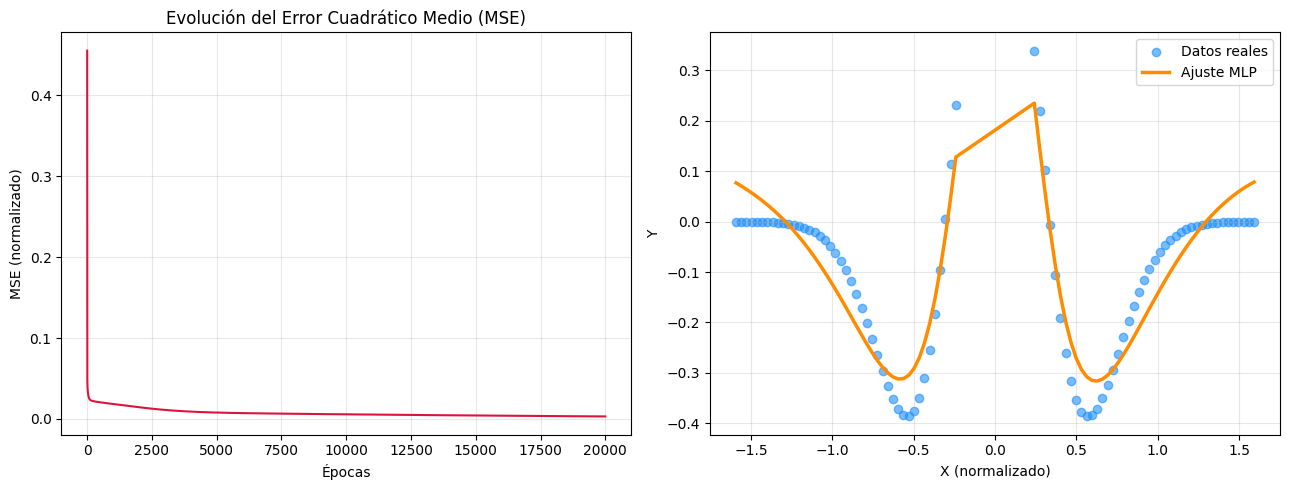

In [33]:
plt.figure(figsize=(13, 5))

# Gráfica de error
plt.subplot(1, 2, 1)
plt.plot(mlp.loss_history, color='crimson')
plt.title("Evolución del Error Cuadrático Medio (MSE)")
plt.xlabel("Épocas")
plt.ylabel("MSE (normalizado)")
plt.grid(True, alpha=0.3)

# Gráfica de la función aprendida
plt.subplot(1, 2, 2)
# Ordenamos para pintar una línea limpia
sort_idx = np.argsort(X_norm.flatten())
plt.scatter(X_norm, y, color='dodgerblue', alpha=0.6, label='Datos reales')
plt.plot(X_norm[sort_idx], y_pred[sort_idx], color='darkorange', linewidth=2.5, label='Ajuste MLP')
plt.xlabel("X (normalizado)")
plt.ylabel("Y")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("resultado_entrenamiento.png", dpi=150)
plt.show()